## Parametric qEDMD

In [ ]:
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import jax.random as random
import importlib
import optimal_schrodinger
importlib.reload(optimal_schrodinger)
from optimal_schrodinger import OptimalSchrodinger, psi_1D
import sys
sys.path.append("/home/s2421480/Documents/PhD_first_year/Extended_summer_project/Codes/d3s/")
import d3s.domain as domain
from scipy.special import hermite, factorial
from math import pi, sqrt


plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'          # or 'sans-serif', 'monospace', etc.
plt.rcParams['font.serif'] = ['Computer Modern Serif']  # You can specify specific fonts

In [2]:
# domain
bounds = jnp.array([[-5, 5]])
boxes = jnp.array([500])
Omega = domain.discretization(bounds, boxes)
c = jnp.array(Omega.midpointGrid(), dtype='float64')

# system
h  = 1
m0 = 1
omega = 1
dimension = Omega.dimension()

#potential qho
def c0(x):
    return m0*omega**2*x**2/2

# #potential Poschl-Teller
# def c0(x, s=1):
#     return -s*(s+1)/(2*jnp.cosh(x)**2) 

def c2(x):
    return -h**2/(2*m0)

# data
key = random.PRNGKey(seed=0)
m = 500
X = np.linspace(bounds[0][0], bounds[0][1], m).reshape(1, -1)
#X = random.uniform(key=key, shape=(1, m), minval=bounds[0][0], maxval=bounds[0][1])

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
/tmp/ipykernel_11787/516916644.py:5: UserWarning: Explicitly requested dtype float64 requested in array is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  c = jnp.array(Omega.midpointGrid(), dtype='float64')


In [3]:
n1 = 10
n2 = 10
n = n1 + n2                                                           # Number of basis functions 
cl = jnp.linspace(-5, 0, n1)
cr = jnp.linspace(0, 5, n2)                                           # Centers
C = jnp.hstack((cl, cr))

sigmas = 0.3*jnp.ones(C.shape)                                        # Initial bandwidth
S_init = jnp.zeros((C.shape[0], C.shape[0]))
epss = 1e-3
loops = 1000
W_init = jnp.c_[sigmas, C]

psi_params = psi_1D
optim = 'adam'

optimalS = OptimalSchrodinger(epss=epss, loops=loops, psi_params=psi_params, c0=c0, c2=c2)

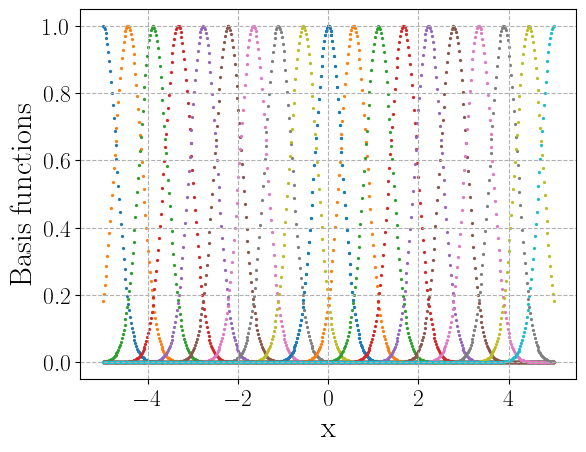

In [4]:
# Visualization of initial basis functions

plt.figure()
for i in range(n):
    plt.scatter(X.T, optimal_schrodinger.basis_func_1D(X, W_init[i, 0], W_init[i, 1]), s=1.7)

# change to plt.plot with less points

plt.grid(which='minor', linestyle=':')
plt.grid(which='major', linestyle='--')
plt.ylabel('Basis functions', fontsize=22)
plt.xlabel('x', fontsize=22)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.show()


In [5]:
Ab, db, Vb, errorb = optimalS.param_qedmd(X, W_init, evs=20)
print('Reconstruction error before optimization: ', errorb)

##initial
eigfuncs = Vb.T @ psi_1D(X, W_init) 
ind, = jnp.where(abs(db) > 0.1)
ind = jnp.sort(ind)[::-1]
# plt.figure(figsize=(4, 3))
# plt.title('Initial eigenfunctions')
# for i in ind[-3:]:
#     Omega.plot(-jnp.real(PsiC[i,:]/jnp.amax(abs(PsiC[i,:]))))
#     plt.ylim((-1, 1))
#     plt.title('lambda = %f' % db[i])

Reconstruction error before optimization:  50.081326


/home/s2421480/miniconda3/envs/pypr-25/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/s2421480/miniconda3/envs/pypr-25/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


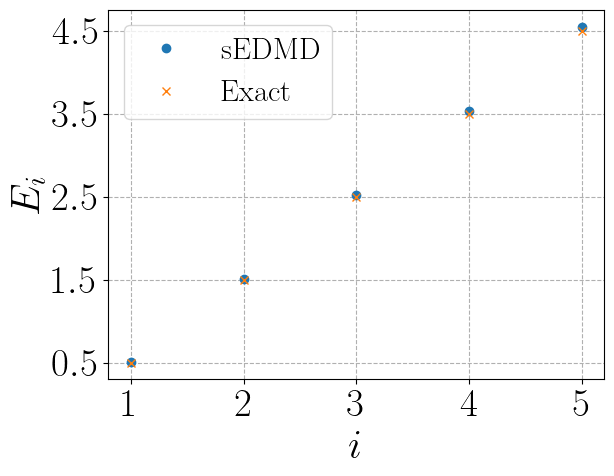

In [ ]:
plt.figure()
xv = jnp.linspace(1, 5, 5)
exact_eig = [omega*(i + 1/2) for i in range(5)]
plt.plot(xv, db[ind][:5], 'o', label='sEDMD')
plt.plot(xv, exact_eig, 'x', label='Exact')
plt.legend(fontsize=22)
plt.grid(which='major', linestyle='--')
plt.xlabel(r'$i$', fontsize=30)
plt.ylabel(r'$E_i$', fontsize=30)
plt.xticks(xv, fontsize=28)
plt.yticks(jnp.arange(0.5, 5, 1), fontsize=28)
#plt.savefig('./figures/chap3_qho_eigvals.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:

# Generate functions for n = 0 to 4
def generate_wavefunctions(x_vals, k, omega=1.0):
    def psi_n(x, n, omega=1.0):
        Hn = hermite(n)
        prefactor = (sqrt(omega) / (pi**0.5 * 2**n * factorial(n)))**0.5
        argument = sqrt(omega) * x
        return prefactor * np.exp(-0.5 * omega * x**2) * Hn(argument)
    return [psi_n(x_vals, n, omega) for n in range(k)]

true_eigf_qho = np.array(generate_wavefunctions(X.squeeze(), 5, omega=omega))


In [8]:

for i in range(5):
    V_exact = true_eigf_qho[-i, :]
    V_1 = eigfuncs[ind[-i],:]
    V_2 = -eigfuncs[ind[-i],:]
    e1 = np.linalg.norm(V_exact-V_1)
    e2 = np.linalg.norm(V_exact-V_2)
    if i == 2:
        eigfuncs = eigfuncs.at[ind[i],:].set(eigfuncs[ind[i],:])
    elif e1 > e2:
        eigfuncs = eigfuncs.at[ind[i],:].set(-eigfuncs[ind[i],:])

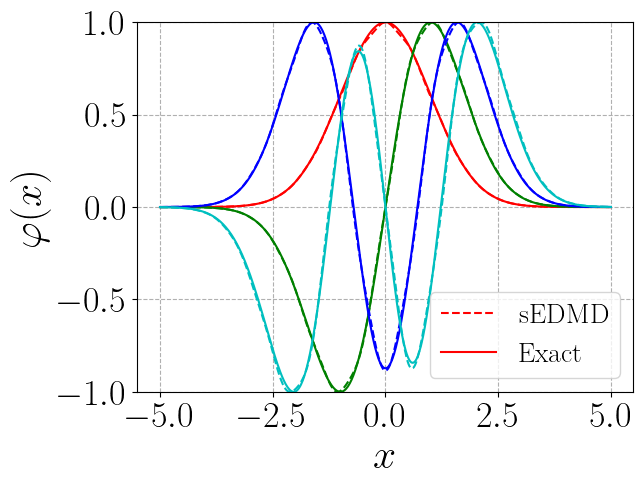

In [ ]:
markers_exact = ['x', '-x', '-x', '-x', '-x']  # Define marker style for exact eigenfunctions
markers_approx = ['o', 'o', 'o', 'o', 'o']  # Define marker style for approximated eigenfunctions
colors_ = ['r', 'g', 'b', 'c', 'm']  # Define colors for each eigenfunction

fig, ax = plt.subplots()
for i in range(4):    
    plt.plot(X.squeeze(), np.real(eigfuncs[ind[i],:]/np.amax(abs(eigfuncs[ind[i],:]))), linestyle='--', color=colors_[i], label = 'sEDMD' if i == 0 else None)
    plt.plot(X.squeeze(), np.real(true_eigf_qho[i,:]/np.amax(abs(true_eigf_qho[i,:]))), linestyle='-',  color=colors_[i], label='Exact' if i == 0 else None) #s=2.2, color=colors_[i], marker=markers_exact[i], label='Exact' if i == 0 else None)
    plt.ylim((-1, 1))
    plt.grid(which='minor', linestyle=':')
    plt.grid(which='major', linestyle='--')
    plt.xlabel('$x$', fontsize=30)
    plt.ylabel(r'$\varphi(x)$', fontsize=30)
    plt.legend(fontsize=20, loc='lower right')
    plt.xticks(np.arange(-5, 6, 2.5), fontsize=26)
    plt.yticks(np.arange(-1, 1.2, .5), fontsize=26)
    #plt.savefig('./figures/chap3_qho_eigfuncs.pdf', bbox_inches='tight', dpi=300)
    #plt.show()